<a href="https://colab.research.google.com/github/Ekimxii/fitness_pose_tracker/blob/main/checkpoint_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Checkpoint model

A model that looks at one frame and says which of the 10 poses it shows: one of the 5 exercises (squats, push-ups, pull-ups, sit-ups, jumping jacks), up or down. Live, it tells `issue_flagger.py` when a checkpoint is reached (the bottom of a squat), so the pose there can be compared with `form_reference_rules.csv`.

This notebook trains and evaluates the model and saves it to `models/checkpoint_model.joblib`. Everything that also runs live is in `checkpoints.py` and imported from there, so training and the live app compute the features the same way.

1. Load the Kaggle frames and compute the features
2. Compare models and features with cross-validation
3. See what the chosen model gets wrong
4. Train it on every frame and save it

In [1]:
import os, sys
if os.path.exists("../features.py"):
    os.chdir("..")
    sys.path.insert(0, os.getcwd())

# Setup: the Kaggle data, and our shared modules (Colab downloads them; locally they're already here)
import os
for module in ["features.py", "reps.py", "checkpoints.py"]:
    if not os.path.exists(module):
        !wget -q https://raw.githubusercontent.com/Ekimxii/fitness_pose_tracker/main/{module}

import kagglehub
import numpy as np
import pandas as pd

import checkpoints
from features import ALL_ANGLES, LANDMARK_COLS, LANDMARKS
from reps import load_training_data

# One row per frame: its landmarks, plus "pose" (e.g. "squats_down"), "exercise" and "position"
data = load_training_data(kagglehub.dataset_download("muhannadtuameh/exercise-recognition"))

# The model's inputs: the 12 joint angles, then the on-screen measures (tilts, heights, widths)
X = checkpoints.pose_features(data[LANDMARK_COLS].to_numpy().reshape(len(data), len(LANDMARKS), 3))
codes, poses = pd.factorize(data["pose"], sort=True)   # models want the poses as numbers 0-9
exercise = np.array([pose.rsplit("_", 1)[0] for pose in poses])   # "squats_down" -> "squats"
print(f"{len(data)} frames, {len(poses)} poses, {X.shape[1]} features ({len(ALL_ANGLES)} angles + {X.shape[1] - len(ALL_ANGLES)} on-screen)")

1372 frames, 10 poses, 35 features (12 angles + 23 on-screen)


## Compare models and features

Random forest (what the rep counter uses) against XGBoost, each on the 12 angles alone and on all the features. 5-fold cross-validation: every frame is predicted by a model trained on the other 80% of frames. As in `form_model.ipynb`, a random split is fine for this data, because neighbouring frames are barely more alike than random frames of the same pose.

Live, the exercise is already known, so only its own up and down compete. The last two columns score that.

In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
from xgboost import XGBClassifier

def xgboost():
    # 150 rounds score the same as form_model.ipynb's 300 here, and predict a live frame twice as fast
    return XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8, random_state=0)

def random_forest():
    return RandomForestClassifier(n_estimators=150, random_state=0)

def cross_validate(make_model, columns):
    """P(each pose) for every frame, each predicted by a model that never saw it."""
    proba = np.zeros((len(X), len(poses)))
    for train_i, test_i in StratifiedKFold(5, shuffle=True, random_state=0).split(X, codes):
        proba[test_i] = make_model().fit(X[train_i, columns], codes[train_i]).predict_proba(X[test_i, columns])
    return proba

def scores(proba):
    predicted = proba.argmax(axis=1)
    known = np.where(exercise == exercise[codes][:, None], proba, -1).argmax(axis=1)   # other exercises ruled out
    return {"pose accuracy": (predicted == codes).mean(),
            "pose macro F1": f1_score(codes, predicted, average="macro"),
            "exercise accuracy": (exercise[predicted] == exercise[codes]).mean(),
            "up/down accuracy (exercise known)": (known == codes).mean(),
            "up/down macro F1 (exercise known)": f1_score(codes, known, average="macro")}

feature_sets = {"12 angles": slice(len(ALL_ANGLES)), "angles + on-screen": slice(None)}
models = {"random forest": random_forest, "XGBoost": xgboost}
cv = {(features, name): cross_validate(make, columns)
      for features, columns in feature_sets.items() for name, make in models.items()}
pd.DataFrame({key: scores(proba) for key, proba in cv.items()}).T.rename_axis(["features", "model"]).round(3)

pose accuracy  pose macro F1  \
features           model                                         
12 angles          random forest          0.758          0.755   
                   XGBoost                0.759          0.757   
angles + on-screen random forest          0.864          0.861   
                   XGBoost                0.870          0.868   

                                  exercise accuracy  \
features           model                              
12 angles          random forest              0.777   
                   XGBoost                    0.774   
angles + on-screen random forest              0.878   
                   XGBoost                    0.887   

                                  up/down accuracy (exercise known)  \
features           model                                              
12 angles          random forest                              0.950   
                   XGBoost                                    0.955   
angles + on-screen random forest                              0.969   
                   XGBoost                                    0.961   

                                  up/down macro F1 (exercise known)  
features           model                                             
12 angles          random forest                              0.949  
                   XGBoost                                    0.952  
angles + on-screen random forest                              0.967  
                   XGBoost                                    0.959

**What this shows.** The features matter more than the model. Adding the on-screen measures lifts pose accuracy from 76% to 87%, while random forest and XGBoost stay within a point of each other on either set of features. With the exercise known, up or down is right about 96% of the time.

The two models are a tie: each is ahead of the other on one measure by less than a point. XGBoost is the one saved below, as planned in the 11/7 meeting notes.

## What the chosen model gets wrong

XGBoost on all the features, still from cross-validation. Each row of the chart is one true pose and shows what its frames were predicted as.

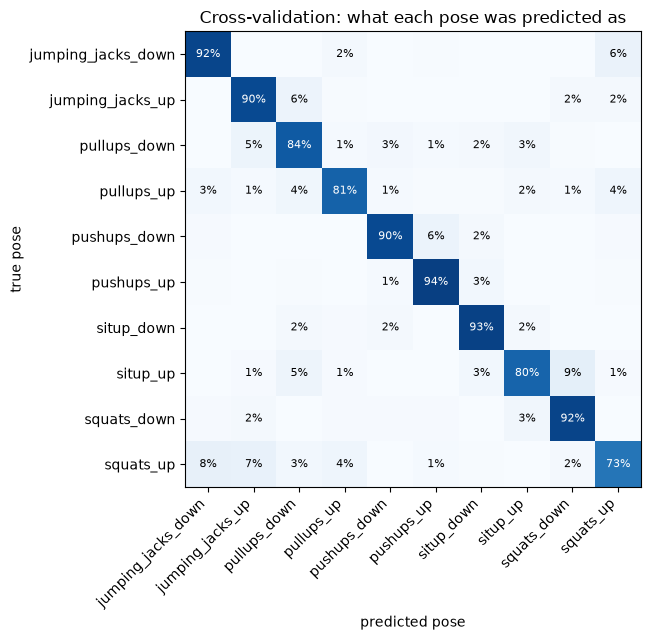

,precision,recall,f1-score
jumping_jacks_down,0.91,0.92,0.91
jumping_jacks_up,0.88,0.90,0.89
pullups_down,0.83,0.84,0.83
pullups_up,0.88,0.81,0.84
pushups_down,0.89,0.90,0.90
pushups_up,0.91,0.94,0.92
situp_down,0.87,0.93,0.90
situp_up,0.85,0.80,0.82
squats_down,0.87,0.92,0.89
squats_up,0.80,0.73,0.77


In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

predicted = cv["angles + on-screen", "XGBoost"].argmax(axis=1)
share = confusion_matrix(codes, predicted, normalize="true")   # each row adds up to 100%

fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(poses)), poses, rotation=45, ha="right")
ax.set_yticks(range(len(poses)), poses)
for (row, col), v in np.ndenumerate(share):
    if v >= 0.01:
        ax.text(col, row, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white" if v > 0.5 else "black")
ax.set(xlabel="predicted pose", ylabel="true pose", title="Cross-validation: what each pose was predicted as")
plt.tight_layout()
plt.show()

# Per pose: precision (of the frames predicted as it, how many were it), recall (of its frames, how many were found), F1
report = classification_report(codes, predicted, target_names=poses, output_dict=True)
pd.DataFrame(report).T.loc[list(poses), ["precision", "recall", "f1-score"]].round(2)

**What this shows.** Most mistakes are between exercises, not between up and down. The weakest pose is `squats_up` (73% found): standing upright also looks like the jumping-jack poses (15% of its frames). `situp_up` is taken for `squats_down` in 9% of its frames, since both are a seated shape.

These mix-ups don't reach the live app, where the exercise is known and only its own up and down compete.

## Train on every frame and save

The model the live app uses is trained on all the frames. `checkpoints.save` stores it with what `CheckpointTracker` needs beside it (the pose names, the feature names, and each exercise's typical joint angles at rest and at work).

Saved checkpoint_model.joblib (1.8 MB)


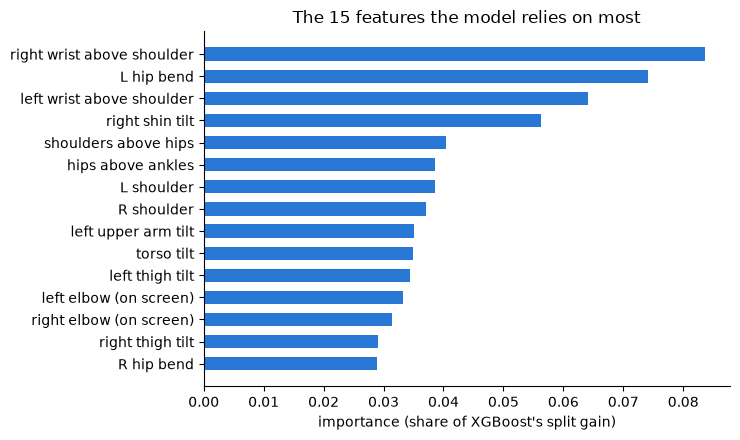

In [4]:
model = xgboost().fit(X, codes)
checkpoints.save(model, poses, data)
print(f"Saved {checkpoints.MODEL.name} ({checkpoints.MODEL.stat().st_size / 1e6:.1f} MB)")

# Which features the saved model relies on most
importance = pd.Series(model.feature_importances_, index=checkpoints.FEATURES).nlargest(15).sort_values()
labels = [ALL_ANGLES.get(name, name) for name in importance.index]   # the angles by their short labels
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.barh(labels, importance.values, color="#2a78d6", height=0.6)
ax.set(xlabel="importance (share of XGBoost's split gain)", title="The 15 features the model relies on most")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**What this shows.** 11 of the 15 are on-screen measures rather than joint angles. How high the hands are leads: it separates the poses with the arms overhead (pull-ups, the top of a jumping jack) from the rest.

To use the new model, nothing else is needed: `live.py` loads `models/checkpoint_model.joblib` when it starts.